# PCA on business features

PCA on 36 business features: explained variance, component weights and component selection.

Saved outputs are from the original coursework run, before the small fixes in this copy. The notebooks have not been rerun.


In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Load all columns into a Pandas DataFrame
df = pd.read_excel('data/business_data_encrypted.xlsx')

# Specify the columns you want to keep for PCA
columns_to_keep = list(df.columns[30:66])

# Load only the specified columns into a Pandas DataFrame
df_selected = df[columns_to_keep].copy()

# Drop any rows with missing values if necessary
df_selected.dropna(inplace=True)

# Standardize the data
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_selected), columns=df_selected.columns)

# Apply PCA to the standardized data
pca = PCA()
pca_result = pca.fit_transform(df_scaled)

# Create a DataFrame to store the PCA results
pca_summary = pd.DataFrame({
    'Principal Component': range(1, pca.n_components_ + 1),
    'Explained Variance': pca.explained_variance_ratio_,
    'Cumulative Explained Variance': np.cumsum(pca.explained_variance_ratio_)
})


# 1. Principal Components Analysis Summary:

Analysis/Comments:

The following  section provides a summary of the principal components, including the explained variance and cumulative explained variance for each principal component.
The explained variance indicates the proportion of the dataset's variance captured by each principal component.
The cumulative explained variance shows the total variance explained as more components are added.


In [ ]:
# Display the PCA summary
print("Principal Components Analysis Summary:")
print(pca_summary)

Principal Components Analysis Summary:
    Principal Component  Explained Variance  Cumulative Explained Variance
0                     1            0.152777                       0.152777
1                     2            0.121116                       0.273893
2                     3            0.080859                       0.354752
3                     4            0.053931                       0.408683
4                     5            0.050066                       0.458749
5                     6            0.046534                       0.505284
6                     7            0.044830                       0.550114
7                     8            0.040826                       0.590940
8                     9            0.039379                       0.630319
9                    10            0.030674                       0.660993
10                   11            0.028723                       0.689716
11                   12            0.028009                  

# Conclusion:

Understanding the explained variance is crucial for determining how much information each principal component retains.
It helps in deciding how many components to keep for a desired level of information retention.

# 2. Loadings of each original feature on each principal component:

Analysis/Comments:

The following section displays the loadings of each original feature on each principal component. The table contains PCA component weights; these are not directly feature–component correlations.
Features with higher absolute loadings have more influence on the corresponding principal component.

In [ ]:
# Create a DataFrame for the loadings
loadings = pd.DataFrame(pca.components_.T, columns=['PC{}'.format(i) for i in range(1, pca.n_components_ + 1)], index=df_selected.columns)

# Display the loadings in a formatted way
print("\nLoadings of each original feature on each principal component:")
print(loadings)

Loadings of each original feature on each principal component:
          PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
x1   0.116942 -0.396854 -0.055599 -0.107361 -0.018603 -0.042472 -0.072309   
x2   0.404562  0.095680 -0.000665  0.031008 -0.008878  0.022902 -0.016977   
x3   0.008628 -0.017553  0.122094  0.095471 -0.280924 -0.492082 -0.016123   
x4   0.393310  0.110273 -0.002796  0.029902  0.020980  0.006121 -0.011544   
x5   0.104614 -0.152020 -0.014323 -0.007785 -0.466072  0.199768  0.121431   
x6   0.405934  0.081654  0.005498  0.029007 -0.035544  0.035177 -0.010452   
x7   0.070898 -0.323872 -0.033953 -0.299549  0.151549 -0.147399 -0.132025   
x8  -0.007834  0.055071  0.075733 -0.088172 -0.146228  0.146346 -0.139241   
x9   0.077172 -0.369465 -0.099180 -0.010496  0.150727 -0.068017 -0.121597   
x10 -0.005947  0.036702 -0.293188 -0.030985 -0.059629 -0.207050  0.111853   
x11  0.022985 -0.106518 -0.133754  0.248312  0.088912 -0.077564  0.188311   
x12  0.024149

# Conclusion:

Examining loadings can provide insights into which features contribute the most to each principal component. 
This information aids in understanding the underlying structure captured by the principal components.

# 3. Scree Plot:

Analysis/Comments:

The following section produces a scree plot, which is a graphical representation of the explained variance for each principal component and the cumulative explained variance.
The scree plot helps in determining the elbow point, which indicates the optimal number of principal components to retain.

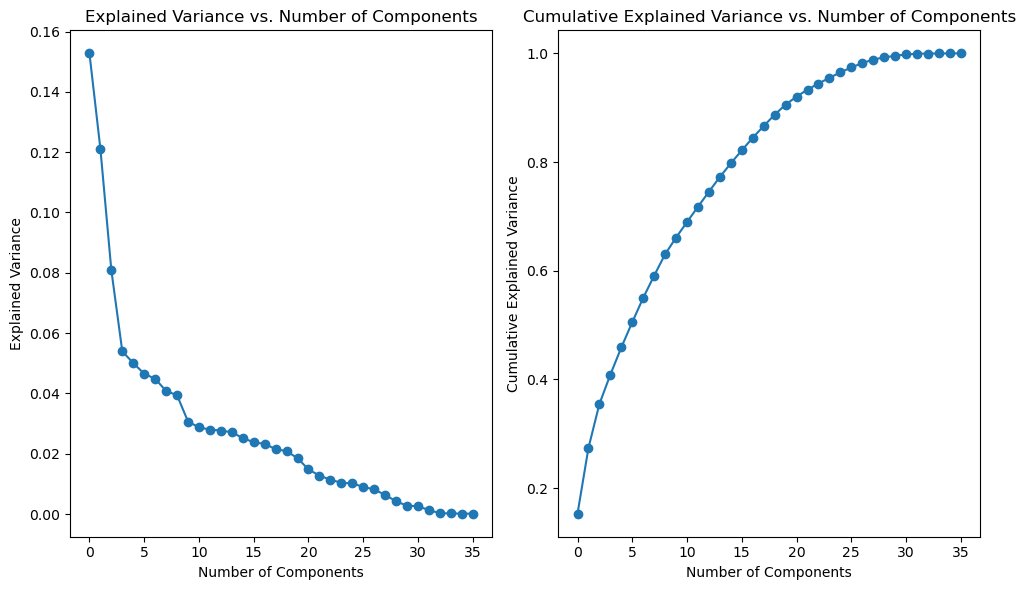

In [ ]:
# Get the explained variance and plot the scree plot
explained_variance = pca.explained_variance_ratio_
cumulative_explained_variance = np.cumsum(explained_variance)

# Plot the scree plot
plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.plot(explained_variance, marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Explained Variance')
plt.title('Explained Variance vs. Number of Components')

plt.subplot(1, 2, 2)
plt.plot(cumulative_explained_variance, marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance vs. Number of Components')

plt.tight_layout()
plt.show()

# Conclusion:

Examining the scree plot assists in deciding the number of components to keep, 
balancing the amount of information retained with the reduction in dimensionality.

# 4. Number of components based on Kaiser criterion:

Analysis/Comments:

The Kaiser criterion is based on eigenvalues, and it suggests keeping components with eigenvalues greater than 1.

In [ ]:
# Step 5: Use the Kaiser criterion to select the number of principal components
eigenvalues = pca.explained_variance_
kaiser_criterion = eigenvalues > 1

# Optionally, you can determine the number of components that meet the Kaiser criterion
num_components_kaiser = sum(kaiser_criterion)
print("Number of components based on Kaiser criterion:", num_components_kaiser)

Number of components based on Kaiser criterion: 12

# Conclusion:

The output indicates the number of components selected based on the Kaiser criterion. 
This can be helpful for automatic determination of the number of components.

# 5. Principal Components DataFrame:

Analysis/Comments:

The following section displays the DataFrame containing the data transformed into the selected number of principal components.

In [ ]:
# Choose the number of components you want to keep (e.g., num_components)
chosen_num_components = num_components_kaiser  # Replace with your desired number

# Initialize PCA with the chosen number of components
pca = PCA(n_components=chosen_num_components)

# Fit and transform the data using the selected number of components
X_pca = pca.fit_transform(df_scaled)

# Create a DataFrame with the principal components
column_names = [f'Principal Component {i + 1}' for i in range(chosen_num_components)]
df_pca = pd.DataFrame(X_pca, columns=column_names)

df_pca.head()

Principal Component 1  Principal Component 2  Principal Component 3  \
0              -0.060736              -0.329736              -0.018335   
1               0.049909              -0.447829              -0.010856   
2              -0.238237              -0.216657              -0.024867   
3              -0.394725               0.151447              -1.375929   
4              -0.406963               0.335285              -0.648380   

   Principal Component 4  Principal Component 5  Principal Component 6  \
0               0.415636               0.488016               0.017151   
1               0.476280               0.550316               0.049741   
2               0.432154               0.490934               0.016436   
3               0.951847              -0.255178              -0.430583   
4               0.479594              -0.187768              -0.396228   

   Principal Component 7  Principal Component 8  Principal Component 9  \
0              -0.589884               

# Conclusion:

The transformed data can be used for further analysis or modeling with reduced dimensionality.

# 6. Explained Variance for Each Principal Component:

Analysis/Comments:

The following bar plot illustrates the explained variance ratio for each principal component.

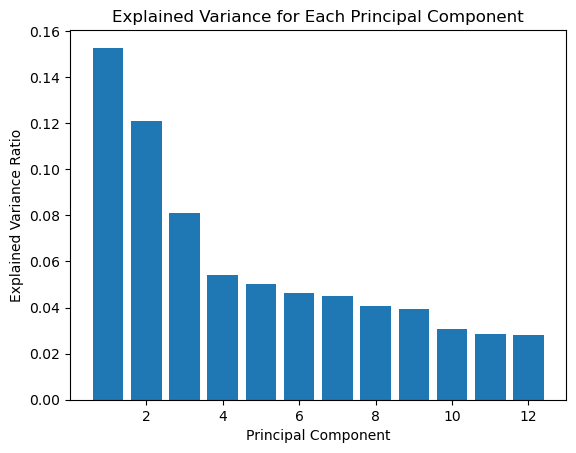

In [ ]:
# Plot the results and output the eigenvalues and Kaiser criterion
plt.bar(range(1, num_components_kaiser+1), pca.explained_variance_ratio_)
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance for Each Principal Component')
plt.show()

# Conclusion:

It provides a visual representation of the contribution of each principal component to the overall variance. 
Higher bars indicate more influential components.

# 7. Eigenvalues and Kaiser Criterion:

Analysis/Comments:

Eigenvalues represent the amount of variance explained by each principal component.
The Kaiser criterion is a boolean array indicating whether the corresponding eigenvalue is greater than 1.

In [ ]:
print("Eigenvalues:", eigenvalues)
print("Kaiser Criterion:", kaiser_criterion)

Eigenvalues: [5.50113752e+00 4.36108708e+00 2.91152828e+00 1.94191172e+00
 1.80276010e+00 1.67558721e+00 1.61423398e+00 1.47005496e+00
 1.41793041e+00 1.10448426e+00 1.03424909e+00 1.00852102e+00
 9.96290711e-01 9.76333168e-01 9.06419319e-01 8.57053345e-01
 8.36825323e-01 7.75349946e-01 7.49942250e-01 6.66985696e-01
 5.31912100e-01 4.58816058e-01 4.09511882e-01 3.72849890e-01
 3.65507446e-01 3.23333944e-01 2.93957804e-01 2.27538726e-01
 1.51832466e-01 9.85858875e-02 9.33947272e-02 4.65423940e-02
 9.76123315e-03 6.70705792e-03 5.04870075e-03 3.54410078e-03]
Kaiser Criterion: [ True  True  True  True  True  True  True  True  True  True  True  True
 False False False False False False False False False False False False
 False False False False False False False False False False False False]

# Conclusion:

Examining eigenvalues and the Kaiser criterion can help in understanding the significance 
of each principal component and deciding which ones to retain.

# Overall Conclusion:

The script successfully performs PCA on the given dataset, providing a comprehensive analysis of the principal components.

The scree plot, Kaiser criterion, and explained variance analysis assist in determining the optimal number of components to retain.

The transformed data (principal components) can be used for subsequent analysis or modeling with reduced dimensionality.